# California 500 hPa ridging / 700 hPa warm-anomaly events (Jan-Apr, 1990-2025)

This notebook finds persistent periods (5+ consecutive days) when the California-box
average of **500 hPa geopotential height** (Z500, ridging/blocking) or **700 hPa
temperature** (T700, warm spells) is more than 1, 2, or 3 standard deviations (σ)
above normal, using ERA5 reanalysis data.

**Inputs:** `z500_t700_ca_<year>.nc`, produced by `get_z500_t700_ca.py` and
`job_array_get_z500_t700_ca.pbs`. One file per year, each with daily-mean 500 hPa
height (m) and 700 hPa temperature (K) over a California bounding box
(32.0-42.5N, 125.0-114.0W), for January-April only.

**Methodology**
- **Box average:** cosine-latitude-weighted mean over the CA box, one value per day per variable.
- **Climatology:** for each calendar day, the mean and standard deviation are computed by pooling that day ± 5 days across all 36 years (1990-2025). This gives a reasonable sample size per calendar day (~36 years × 11 days ≈ 400 samples) while still tracking the Jan-Apr seasonal warming trend.
- **Detrending:** a linear year-trend is fit and removed from the climatology before standardizing. Z500 has a real trend (+7.4 m/decade, p=0.045); T700's trend is smaller and not significant (+0.2 K/decade, p=0.17), but it is removed too for consistency.
- **Standardized anomaly** = (value − detrended climatological mean) / climatological standard deviation, for that calendar day.
- "Ridging/blocking" and "warm" are defined as **positive** anomalies (height anomaly > 0 → ridge; temperature anomaly > 0 → warm). Set `SIGN = -1` in the event-detection cell to study troughs/cold spells instead.
- A run of days above threshold is **one event**, regardless of length. The run is gap-tolerant: up to `MAX_GAP` sub-threshold days within an otherwise persistent run do not split it into two events, since a real blocking regime can briefly dip below threshold (e.g. when reinforced by an impinging eddy) and then reintensify without that being a new episode. Events shorter than `MIN_DURATION` days are dropped.

Ming Ge, Oct 2026

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))  # 1990-2025 inclusive, excludes 2026
CLIM_WINDOW = 5                  # +/- days pooled around each calendar day for climatology
MIN_DURATION = 5                 # minimum consecutive days to count as an event
MAX_GAP = 1                      # max sub-threshold calendar days tolerated within an
                                 # event before it's considered two separate events --
                                 # lets a quasi-persistent, eddy-reinforced block that
                                 # briefly dips below threshold stay one event instead
                                 # of fragmenting into several
THRESHOLDS = [1, 2, 3]           # standard deviations
SIGN = 1                         # +1 = ridging/warm (as requested); -1 = troughs/cold

## 1. Load the CA-box daily data and build the box-averaged time series

Loads the per-year NetCDF files and computes the cosine-latitude-weighted daily box
average of Z500 and T700, as described in the Methodology above.

In [2]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in files if not f.exists()]
if missing:
    raise FileNotFoundError(
        f'{len(missing)} year file(s) missing from {DATA_DIR}: {missing[:5]}...\n'
        'Run job_array_get_z500_t700_ca.pbs first (see get_z500_t700_ca.py).'
    )

ds = xr.open_mfdataset(files, combine='by_coords')

In [3]:
# cosine-latitude-weighted box average -> one value per day per variable
weights = np.cos(np.deg2rad(ds.latitude))
z500_box = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
t700_box = ds.t700.weighted(weights).mean(dim=('latitude', 'longitude')).compute()

df = pd.DataFrame(
    {'z500': z500_box.values, 't700': t700_box.values},
    index=pd.to_datetime(ds.time.values),
).sort_index()

# keep January-April only, in case the source files carry a stray day
df = df[df.index.month.isin([1, 2, 3, 4])]
print(df.shape)
df.head()

(4329, 2)


,z500,t700
1990-01-01,5643.923522,270.726472
1990-01-02,5499.851700,264.173043
1990-01-03,5571.083558,265.430038
1990-01-04,5635.812357,266.935467
1990-01-05,5702.091416,269.826321


## 2. Calendar-day climatology and standardized anomalies

Computes the calendar-day climatology (mean and standard deviation), removes the
linear year-trend, and derives the standardized anomaly used for event detection,
following the Methodology above.

In [4]:
from scipy.stats import linregress

def climatology_dict(time_index, vals, window=CLIM_WINDOW, compute_std=True):
    """Per-calendar-day mean (and optionally std), pooling +/-window days across all
    years, keyed by (month, day) rather than aligned to one specific DataFrame's index --
    that's what makes the same lookup reusable for dates the fit never saw (2026 in
    section 8, or every grid point in section 5b's spatial composites). Pooling always
    happens along axis 0, so `vals` can be a 1-D box-averaged series (time,) or a
    gridded field (time, lat, lon) -- both are used in this notebook.
    time_index: the dates the pooling is computed FROM (e.g. 1990-2025).
    vals: array aligned to time_index, time as axis 0.
    """
    md_key = list(zip(time_index.month, time_index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])
    clim_mean, clim_std = {}, {}
    for k, idx in key_to_idx.items():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        clim_mean[k] = vals[mask].mean(axis=0)
        if compute_std:
            clim_std[k] = vals[mask].std(axis=0)
    return (clim_mean, clim_std) if compute_std else clim_mean


def lookup_climatology(time_index, clim_dict):
    """Expand a (month, day) -> value dict into an array aligned to time_index -- for
    applying a climatology dict (built from some other set of dates/years) to a new
    series, e.g. scoring 2026 (section 8) against the 1990-2025 dict built here."""
    md_key = list(zip(time_index.month, time_index.day))
    return np.array([clim_dict[k] for k in md_key])


def fit_year_trend(df, col, clim_mean, label='', verbose=True):
    """Fit a linear year-trend in the climatology residual. Pooling all 36 years into
    one calendar-day mean (as climatology_dict() does) silently bakes a multi-decadal
    trend into the baseline: anomalies look artificially warm/high in recent years and
    artificially cool/low in the 1990s, independent of actual synoptic extremity, which
    biases event detection toward (or away from) recent years. The trend is estimated
    from annual Jan-Apr means (36 points) rather than daily residuals to avoid
    autocorrelation inflating the apparent significance.
    Returns (trend_per_year, slope, intercept): the per-day-of-df trend array (for
    shifting df's own baseline), and the raw (slope, intercept) for extrapolating the
    same fit to a year outside df's own range (section 8's 2026 test).
    """
    residual = df[col].values - clim_mean
    years = df.index.year.values
    annual_mean_residual = pd.Series(residual, index=years).groupby(level=0).mean()
    slope, intercept, r, p, se = linregress(annual_mean_residual.index.values, annual_mean_residual.values)
    if verbose:
        print(f'{label}{col}: year-trend = {slope * 10:+.3f} per decade (p = {p:.3f}, r = {r:.2f}) '
              f'-- removing this from the climatological baseline before standardizing')
    return intercept + slope * years, slope, intercept


for col in ['z500', 't700']:
    clim_mean, clim_std = climatology_dict(df.index, df[col].values)
    m = lookup_climatology(df.index, clim_mean)
    s = lookup_climatology(df.index, clim_std)
    trend, slope, intercept = fit_year_trend(df, col, m)
    # detrended baseline: the pooled calendar-day climatology, shifted per-year by
    # the fitted linear trend, so each year is compared to its own expected
    # baseline instead of the fixed 36-year pooled average
    df[f'{col}_clim_mean'] = m + trend
    df[f'{col}_clim_std'] = s
    df[f'{col}_anom'] = df[col] - df[f'{col}_clim_mean']
    df[f'{col}_sanom'] = df[f'{col}_anom'] / df[f'{col}_clim_std']

df[['z500', 'z500_clim_mean', 'z500_sanom', 't700', 't700_clim_mean', 't700_sanom']].describe()

z500: year-trend = +7.405 per decade (p = 0.045, r = 0.34) -- removing this from the climatological baseline before standardizing
t700: year-trend = +0.204 per decade (p = 0.168, r = 0.23) -- removing this from the climatological baseline before standardizing


,z500,z500_clim_mean,z500_sanom,t700,t700_clim_mean,t700_sanom
count,4329.000000,4329.000000,4329.000000,4329.000000,4329.000000,4329.000000
mean,5659.962311,5659.950211,0.000094,271.319546,271.318919,-0.000150
std,92.032670,21.294897,0.993207,3.944485,1.193632,0.994326
min,5297.817250,5608.483609,-3.882557,257.827869,268.955988,-3.523486
25%,5597.204648,5646.879036,-0.703784,268.596213,270.608387,-0.683446
50%,5668.574255,5660.245391,0.092674,271.574661,271.226630,0.076724
75%,5728.456609,5672.356068,0.746074,274.193606,271.752745,0.747162
max,5891.593492,5723.341417,2.286580,282.302358,274.944059,2.374307


## 3. Event detection: gap-tolerant runs ≥ `MIN_DURATION` days above threshold

Groups the days where the standardized anomaly exceeds a threshold into events, using
the gap-tolerance rule described above, and saves the resulting event table to CSV.

In [5]:
def find_events(dates, sanom, threshold, min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP):
    """
    Group calendar days where sign*sanom >= threshold into events, tolerating
    short sub-threshold dips (up to max_gap calendar days) within an otherwise
    persistent run -- a quasi-persistent block reinforced by impinging eddies can
    briefly dip below threshold and reintensify without that being two events.

    Only merges gaps *within* one calendar-contiguous stretch of data: a gap
    across the real Apr->Jan year boundary is never bridged, since that date jump
    is far larger than any reasonable max_gap.
    """
    exceed = (sign * sanom) >= threshold
    n = len(dates)

    # label each day with the id of its calendar-contiguous segment (breaks only
    # at a true date gap, e.g. Apr 30 -> Jan 1 of the next year)
    seg_id = np.zeros(n, dtype=int)
    for i in range(1, n):
        seg_id[i] = seg_id[i - 1] + (1 if (dates[i] - dates[i - 1]).days != 1 else 0)

    records = []
    for seg in np.unique(seg_id):
        idx = np.where(seg_id == seg)[0]
        seg_exceed = exceed[idx]

        # raw contiguous exceed-runs within this segment
        runs = []
        start = None
        for j, val in enumerate(seg_exceed):
            if val and start is None:
                start = j
            elif not val and start is not None:
                runs.append((start, j - 1))
                start = None
        if start is not None:
            runs.append((start, len(seg_exceed) - 1))

        # merge runs separated by <= max_gap sub-threshold days
        merged = []
        for run in runs:
            if merged and run[0] - merged[-1][1] - 1 <= max_gap:
                merged[-1] = (merged[-1][0], run[1])
            else:
                merged.append(list(run))
        merged = [tuple(m) for m in merged]

        for js, je in merged:
            s, e = idx[js], idx[je]
            duration = je - js + 1
            if duration >= min_duration:
                seg_sanom = sign * sanom[s:e + 1]
                records.append({
                    'start_date': dates[s].date(),
                    'end_date': dates[e].date(),
                    'duration_days': duration,
                    'n_gap_days': int((~exceed[s:e + 1]).sum()),
                    'peak_sanom': seg_sanom.max(),
                    'mean_sanom': seg_sanom.mean(),
                })
    return pd.DataFrame(records)


VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]

all_events = []
dates = df.index
for col, label in VARS:
    sanom = df[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        all_events.append(ev)

events_df = pd.concat(all_events, ignore_index=True)
events_df = events_df.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
print(f'{len(events_df)} events found (>= {MIN_DURATION} days, gap tolerance {MAX_GAP} day(s), sign={SIGN:+d})')
events_df

97 events found (>= 5 days, gap tolerance 1 day(s), sign=+1)


,variable,threshold_sd,start_date,end_date,duration_days,n_gap_days,peak_sanom,mean_sanom
0,500 hPa height (ridging),1,1990-02-21,1990-02-25,5.0,0.0,1.782993,1.509477
1,500 hPa height (ridging),1,1990-03-19,1990-03-23,5.0,0.0,1.428012,1.272548
2,500 hPa height (ridging),1,1990-04-10,1990-04-15,6.0,0.0,1.832694,1.529338
3,500 hPa height (ridging),1,1992-02-21,1992-02-28,8.0,0.0,1.861366,1.541338
4,500 hPa height (ridging),1,1992-04-24,1992-04-29,6.0,0.0,2.047381,1.547013
...,...,...,...,...,...,...,...,...
92,700 hPa temperature (warm),1,2022-02-07,2022-02-14,8.0,0.0,1.778521,1.354442
93,700 hPa temperature (warm),1,2022-03-22,2022-03-27,6.0,0.0,2.206851,1.720008
94,700 hPa temperature (warm),1,2024-01-27,2024-01-31,5.0,0.0,1.561586,1.290536
95,700 hPa temperature (warm),1,2025-02-23,2025-03-01,7.0,0.0,1.487340,1.244969


In [6]:
BASE_OUT_CSV = (
    f'ca_z500_t700_events_1990-2025_detrended_mindur{MIN_DURATION}.csv'
)
# filename is parameterized by MIN_DURATION so this never collides with a
# sibling notebook run at a different persistence threshold (e.g. MIN_DURATION=3
# in CA_z500_t700_blocking_events_detrend_3day.ipynb) -- both used to write the same
# generic 'ca_z500_t700_events_1990-2025_detrended.csv', so whichever notebook
# ran most recently silently clobbered the other's results.
out_csv = DATA_DIR / BASE_OUT_CSV
events_df.to_csv(out_csv, index=False)
print('saved', out_csv)

events_df.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

saved /glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/ca_z500_t700_events_1990-2025_detrended_mindur5.csv


,,n_events,mean_duration,max_duration
variable,threshold_sd,,,
500 hPa height (ridging),1,48,6.791667,12.0
700 hPa temperature (warm),1,49,7.571429,18.0


## 4. Visualization

Plots the detected events as a timeline, summarizes event counts by threshold, and
shows the distribution of event durations.

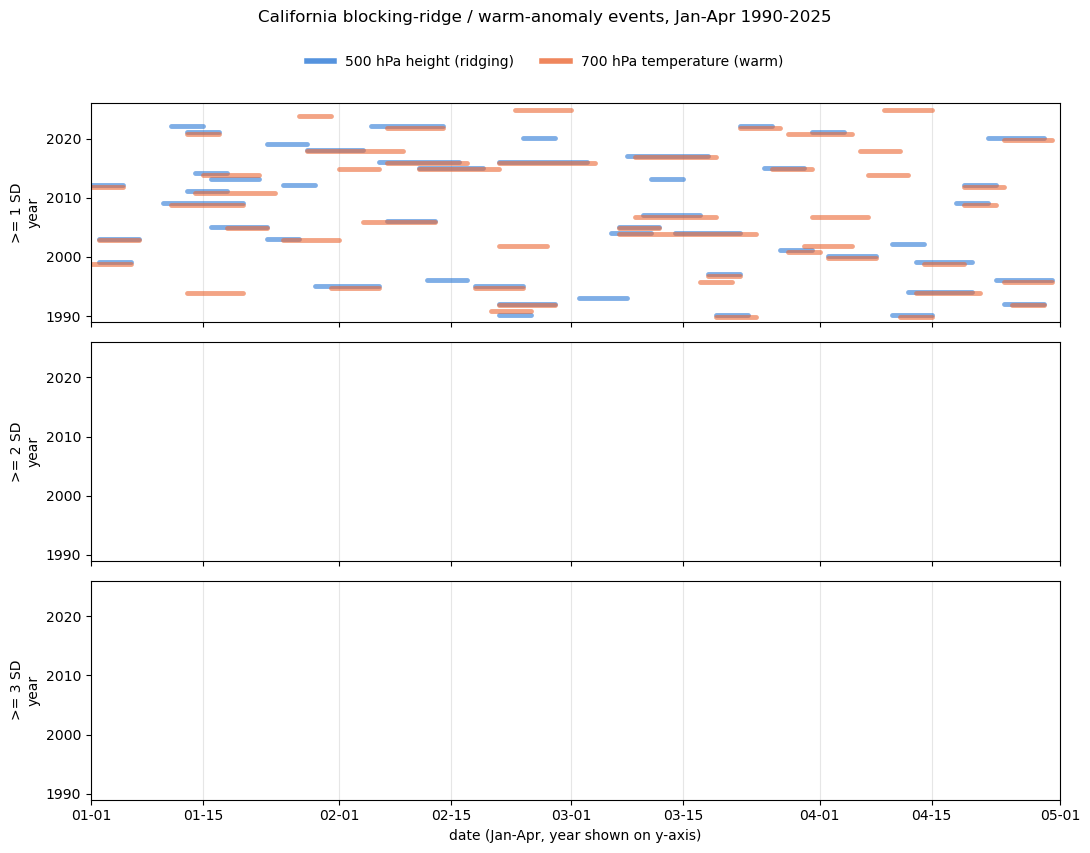

In [7]:
import matplotlib.dates as mdates

COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
Y_OFFSET = {'500 hPa height (ridging)': 0.1, '700 hPa temperature (warm)': -0.18}

fig, axes = plt.subplots(len(THRESHOLDS), 1, figsize=(11, 8), sharex=True)
for ax, thr in zip(axes, THRESHOLDS):
    sub = events_df[events_df.threshold_sd == thr]
    for _, row in sub.iterrows():
        year = row.start_date.year
        x0 = pd.Timestamp(2000, row.start_date.month, row.start_date.day)
        x1 = pd.Timestamp(2000, row.end_date.month, row.end_date.day) if row.end_date.year == row.start_date.year else pd.Timestamp(2000, 4, 30)
        y = year + Y_OFFSET[row.variable]
        ax.plot([x0, x1], [y, y], color=COLOR[row.variable], linewidth=3.5,
                 alpha=0.6, solid_capstyle='round')
    ax.set_ylabel(f'>= {thr} SD\nyear')
    ax.set_ylim(1989, 2026)
    # explicit x-limits instead of matplotlib's default autoscale, which pads a
    # few days into Dec 1999 on the left and cuts awkwardly past Apr 30 on the
    # right; 05-01 gives the last event's line a one-day buffer from the edge.
    ax.set_xlim(pd.Timestamp(2000, 1, 1), pd.Timestamp(2000, 5, 1))
    # ticks as MM-DD, not the full 2000-MM-DD -- the placeholder year 2000 used
    # to lay all events on one calendar axis isn't real data and shouldn't show.
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
    ax.grid(axis='x', color='0.9')
axes[-1].set_xlabel('date (Jan-Apr, year shown on y-axis)')
handles = [plt.Line2D([0], [0], color=c, linewidth=4, alpha=0.8) for c in COLOR.values()]
fig.legend(handles, COLOR.keys(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02), frameon=False)
fig.suptitle('California blocking-ridge / warm-anomaly events, Jan-Apr 1990-2025', y=1.06)
fig.tight_layout()
plt.show()

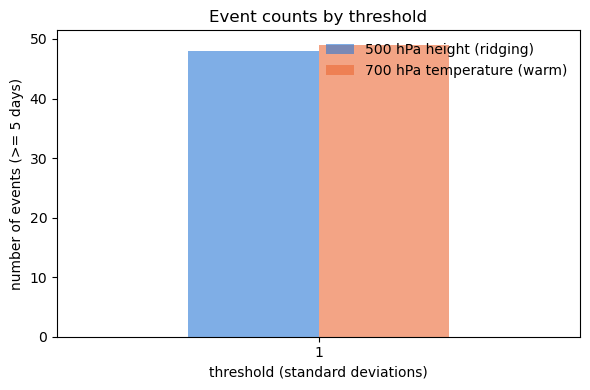

In [8]:
counts = events_df.groupby(['threshold_sd', 'variable']).size().unstack('variable').reindex(columns=COLOR.keys())
ax = counts.plot(kind='bar', color=list(COLOR.values()), figsize=(6, 4), rot=0, alpha=0.6)
ax.set_xlabel('threshold (standard deviations)')
ax.set_ylabel('number of events (>= 5 days)')
ax.set_title('Event counts by threshold')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

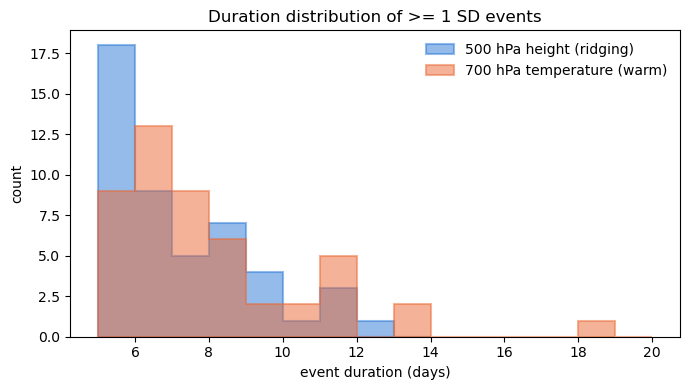

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for col, label in VARS:
    durations = events_df.loc[(events_df.variable == label) & (events_df.threshold_sd == 1), 'duration_days']
    ax.hist(durations, bins=range(5, int(durations.max()) + 3), alpha=0.5, label=label,
             color=COLOR[label], edgecolor=COLOR[label], linewidth=1.5, histtype='stepfilled')
ax.set_xlabel('event duration (days)')
ax.set_ylabel('count')
ax.set_title('Duration distribution of >= 1 SD events')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Validation

Independent checks on whether the detected events reflect a real synoptic signal, not
an artifact of the detection method:
1. **Climatology sanity** — standardized anomalies should have an average near zero and a standard deviation near one.
2. **Physical consistency** — Z500 ridging and T700 warmth should be positively correlated.
3. **Event co-occurrence** — ridging and warm-event days should substantially overlap, both as a day-level fraction and as matched episode-to-episode pairs. The two ways of computing overlap should agree with each other exactly.
4. **Face validity** — known, well-documented persistent-ridge winters over the western US (e.g. the 2013-2015 "Ridiculously Resilient Ridge" and winter 2021-2022) should show up as detected ridging events.
5. **Spatial check** — compositing the full gridded Z500/T700 fields over the detected events (one mean field per *event*, not per day, so a long event does not get more weight than a short one) should show a coherent, basin-scale ridge/warm pattern. A block bootstrap over events (not days, since consecutive days within one event are highly autocorrelated) gives a 95% confidence interval per grid point; hatched regions are not significant at that level.

### Climatology sanity

In [10]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature


def event_days(variable, threshold_sd=1):
    sub = events_df[(events_df.variable == variable) & (events_df.threshold_sd == threshold_sd)]
    days = set()
    for _, row in sub.iterrows():
        days.update(pd.date_range(row.start_date, row.end_date))
    return days


print('Standardized-anomaly sanity check (should be close to mean=0, std=1 if the '
      'calendar-day climatology removed the seasonal cycle correctly):')
df[['z500_sanom', 't700_sanom']].agg(['mean', 'std', 'min', 'max'])

Standardized-anomaly sanity check (should be close to mean=0, std=1 if the calendar-day climatology removed the seasonal cycle correctly):


,z500_sanom,t700_sanom
mean,0.000094,-0.000150
std,0.993207,0.994326
min,-3.882557,-3.523486
max,2.286580,2.374307


### Physical consistency

Correlation between Z500 and T700 standardized anomalies: r = 0.92


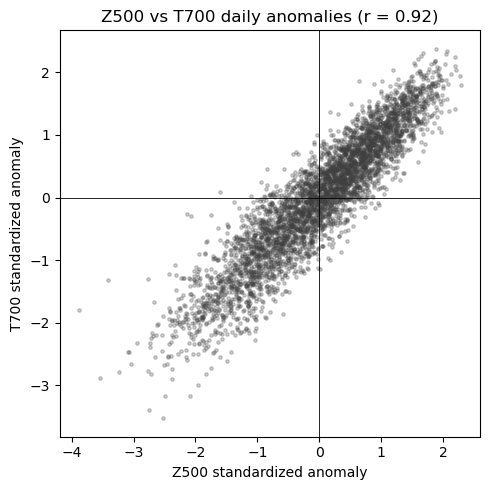

In [11]:
corr = df['z500_sanom'].corr(df['t700_sanom'])
print(f'Correlation between Z500 and T700 standardized anomalies: r = {corr:.2f}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df['z500_sanom'], df['t700_sanom'], s=6, alpha=0.25, color='0.25')
ax.axhline(0, color='k', lw=0.6)
ax.axvline(0, color='k', lw=0.6)
ax.set_xlabel('Z500 standardized anomaly')
ax.set_ylabel('T700 standardized anomaly')
ax.set_title(f'Z500 vs T700 daily anomalies (r = {corr:.2f})')
plt.tight_layout()
plt.show()

### Event co-occurrence (day level)

In [12]:
z_days = event_days('500 hPa height (ridging)', 1)
t_days = event_days('700 hPa temperature (warm)', 1)
overlap = z_days & t_days
print(f'Z500 ridging (>=1 SD) event-days: {len(z_days)}')
print(f'T700 warm (>=1 SD) event-days:    {len(t_days)}')
print(f'Days flagged by both:             {len(overlap)}  '
      f'({100 * len(overlap) / min(len(z_days), len(t_days)):.0f}% of the smaller set)')
print('A high overlap fraction is expected: a 500 hPa ridge drives subsidence that '
      'adiabatically warms the 700 hPa layer beneath it.')

Z500 ridging (>=1 SD) event-days: 326
T700 warm (>=1 SD) event-days:    371
Days flagged by both:             245  (75% of the smaller set)
A high overlap fraction is expected: a 500 hPa ridge drives subsidence that adiabatically warms the 700 hPa layer beneath it.


### Face validity

In [13]:
# Spot-check against documented persistent-ridge winters over the western US/CA.
# Sources (verified by web search, Oct 2026):
# - "Ridiculously Resilient Ridge" (RRR): nickname coined by Daniel Swain (Weather
#   West blog, Dec 2013); formalized in Swain et al. 2015, Geophysical Research
#   Letters 42(22), 9999-10003, doi:10.1002/2015GL066628 ("A tale of two California
#   droughts"). Per that paper, the RRR pattern recurred across winters 2012-13,
#   2013-14, and 2014-15 -- https://en.wikipedia.org/wiki/Ridiculously_Resilient_Ridge
# - Winter 2021-2022: NOAA/CNRFC reported California's driest Jan-Mar in the
#   100-year precipitation record, immediately following the wettest December on
#   record at the UC Berkeley Central Sierra Snow Lab -- CNRFC Water Resources
#   Update, 2022-04-15 (cnrfc.noaa.gov/WaterResourcesUpdates/WRUpdate20220415.pdf)
#   and Washington Post, 2022-03-01.
KNOWN_RIDGE_WINTERS = {
    'winter 2012-2013 (RRR onset)': ('2013-01-01', '2013-04-30'),
    'winter 2013-2014 (RRR, driest CA winter on record)': ('2014-01-01', '2014-04-30'),
    'winter 2014-2015 (RRR persists)': ('2015-01-01', '2015-04-30'),
    'winter 2021-2022 (driest Jan-Mar in 100-yr record, after wettest Dec on record)': ('2022-01-01', '2022-03-31'),
}

z_events = events_df[(events_df.variable == '500 hPa height (ridging)') & (events_df.threshold_sd == 1)]
for name, (lo, hi) in KNOWN_RIDGE_WINTERS.items():
    lo, hi = pd.Timestamp(lo).date(), pd.Timestamp(hi).date()
    hits = z_events[(z_events.start_date <= hi) & (z_events.end_date >= lo)]
    print(f'{name}:')
    if len(hits):
        print(hits[['start_date', 'end_date', 'duration_days', 'peak_sanom']].to_string(index=False))
    else:
        print('  NO ridging event detected in this window -- worth a closer look.')
    print()

winter 2012-2013 (RRR onset):
start_date   end_date  duration_days  peak_sanom
2013-01-16 2013-01-22            7.0    1.476496
2013-03-11 2013-03-15            5.0    1.687232

winter 2013-2014 (RRR, driest CA winter on record):
start_date   end_date  duration_days  peak_sanom
2014-01-14 2014-01-18            5.0    1.636727

winter 2014-2015 (RRR persists):
start_date   end_date  duration_days  peak_sanom
2015-02-11 2015-02-19            9.0    1.892387
2015-03-25 2015-03-30            6.0    1.935295

winter 2021-2022 (driest Jan-Mar in 100-yr record, after wettest Dec on record):
start_date   end_date  duration_days  peak_sanom
2022-01-11 2022-01-15            5.0    1.612349
2022-02-05 2022-02-14           10.0    1.557238
2022-03-22 2022-03-26            5.0    1.895923



### Spatial check

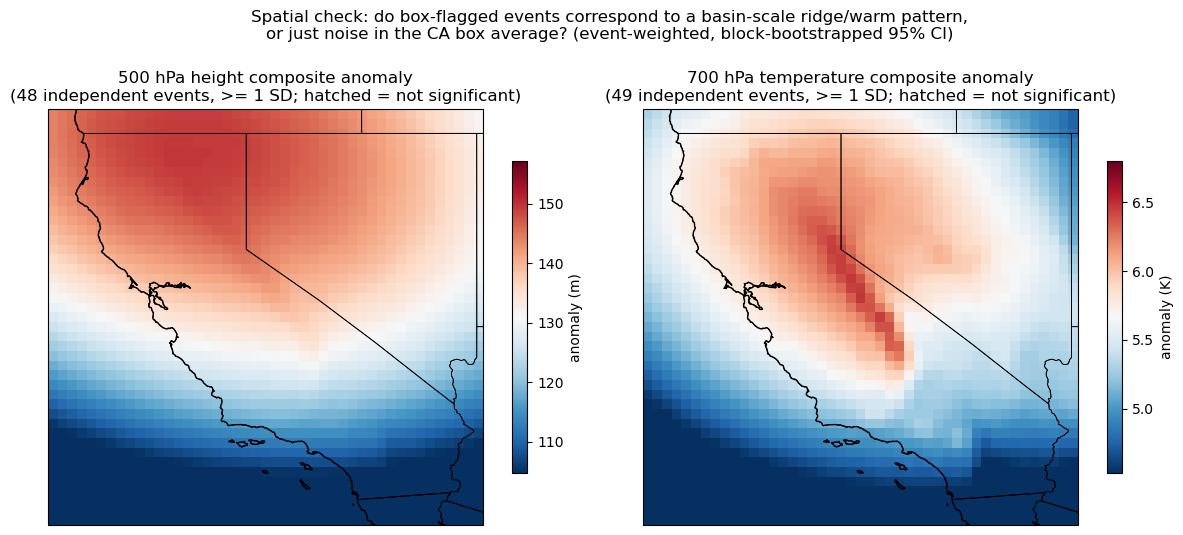

In [14]:
def gridpoint_climatology(da, window=CLIM_WINDOW):
    """Per-calendar-day grid-point anomaly -- reuses climatology_dict()/lookup_climatology()
    from section 2, which pool along axis 0 regardless of trailing shape, so they work
    directly on a gridded (time, lat, lon) field without a separate implementation."""
    time_index = pd.to_datetime(da.time.values)
    vals = da.load().values  # (time, lat, lon)
    clim_mean = climatology_dict(time_index, vals, window, compute_std=False)
    return vals - lookup_climatology(time_index, clim_mean)


def event_mean_fields(events_sub, grid_anom, time_index):
    """One mean anomaly field per event (not per day), averaged over that
    event's own day span -- equal weight per event regardless of duration."""
    fields = []
    for _, row in events_sub.iterrows():
        mask = (time_index.date >= row.start_date) & (time_index.date <= row.end_date)
        fields.append(grid_anom[mask].mean(axis=0))
    return np.stack(fields)


def bootstrap_composite_ci(event_fields, n_boot=1000, seed=42):
    """Block bootstrap over *events* (the actual independent sampling unit --
    days within one event are highly autocorrelated, so resampling days instead
    of events would badly understate the true uncertainty). Returns the 95% CI
    bounds per grid point."""
    rng = np.random.default_rng(seed)
    n_events = event_fields.shape[0]
    boot = np.empty((n_boot,) + event_fields.shape[1:])
    for b in range(n_boot):
        idx = rng.integers(0, n_events, size=n_events)
        boot[b] = event_fields[idx].mean(axis=0)
    return np.percentile(boot, [2.5, 97.5], axis=0)


z500_grid_anom = gridpoint_climatology(ds['z500'])
t700_grid_anom = gridpoint_climatology(ds['t700'])
time_index = pd.to_datetime(ds.time.values)
lon_plot = np.where(ds.longitude.values > 180, ds.longitude.values - 360, ds.longitude.values)

z_events_1sd = events_df[(events_df.variable == '500 hPa height (ridging)') & (events_df.threshold_sd == 1)]
t_events_1sd = events_df[(events_df.variable == '700 hPa temperature (warm)') & (events_df.threshold_sd == 1)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={'projection': ccrs.PlateCarree()})
for ax, grid_anom, events_sub, var_label, units in zip(
    axes,
    [z500_grid_anom, t700_grid_anom],
    [z_events_1sd, t_events_1sd],
    ['500 hPa height', '700 hPa temperature'],
    ['m', 'K'],
):
    event_fields = event_mean_fields(events_sub, grid_anom, time_index)
    composite = event_fields.mean(axis=0)  # equal weight per event
    ci_lo, ci_hi = bootstrap_composite_ci(event_fields)
    not_significant = (ci_lo <= 0) & (ci_hi >= 0)  # zero inside the 95% CI

    # scale the color limits to the actual composite magnitude -- a fixed vmax
    # across variables with very different anomaly scales (tens of m vs a few K)
    # saturates the whole map to one color and hides the spatial structure.
    vmax = np.abs(composite).max() * 1.05
    pcm = ax.pcolormesh(lon_plot, ds.latitude.values, composite, cmap='RdBu_r',
                         vmin=vmax * 2 / 3., vmax=vmax, shading='auto', transform=ccrs.PlateCarree())
    ax.contourf(lon_plot, ds.latitude.values, not_significant.astype(int),
                levels=[0.5, 1.5], colors='none', hatches=['...'],
                transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.STATES, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.6)
    ax.set_title(f'{var_label} composite anomaly\n'
                 f'({len(events_sub)} independent events, >= 1 SD; hatched = not significant)')
    fig.colorbar(pcm, ax=ax, shrink=0.75, label=f'anomaly ({units})')
fig.suptitle(
    'Spatial check: do box-flagged events correspond to a basin-scale ridge/warm pattern,\n'
    'or just noise in the CA box average? (event-weighted, block-bootstrapped 95% CI)',
    y=1.06,
)
plt.tight_layout()
plt.show()

**Note:** this table is from an earlier, pre-detrending run at the same
`MIN_DURATION=5`. It has been verified against the pre-detrend comparison recomputed
below and is kept here for reference.

For Jan-Apr 1990-2025, the standardized anomalies reach the following extremes:

| | max σ reached | days ≥2σ | longest run ≥2σ | days ≥3σ |
|---|---|---|---|---|
| Z500 | 2.26 | 24 of 4329 | 2 days | 0 |
| T700 | 2.41 | 27 of 4329 | 3 days | 0 |

- **3σ never happens:** the standardized anomaly never reaches 3σ for either variable in this 36-year record, so that threshold is empty by construction, not a detection failure.
- **2σ happens but never persists:** it occurs on ~25 days total, but the longest unbroken run is only 2-3 days — well short of the 5-day minimum. A single day spiking to 2σ and relaxing the next day is common; staying above 2σ for 5 straight days essentially never happened in this record.
- **1σ is where persistence shows up:** runs there reach up to 12 days (Z500) and 18 days (T700).

Two factors make 2-3σ persistence this rare: box-averaging over the whole CA domain
smooths out local extremes, and the narrow ±5-day climatology window already resolves
much of the "expected" synoptic variance into the mean, leaving a tighter anomaly than
a coarser monthly climatology would give.

To get more 2σ/3σ events, shrink `MIN_DURATION`, or shrink the spatial average
(sub-box or single grid point) so extremes are not averaged away.

In [15]:
# Pre-detrend vs detrended comparison, computed here for THIS notebook's own
# parameters (MIN_DURATION=5). An earlier version of the next markdown cell
# quoted pre/post event counts (107/115, 110, etc.) that actually came from
# the MIN_DURATION=3 sibling notebook (CA_z500_t700_blocking_events_detrend_3day.ipynb),
# not this one -- recomputing live here avoids that mismatch happening again.
df_pre = df.copy()
for col in ['z500', 't700']:
    clim_mean, clim_std = climatology_dict(df.index, df[col].values)
    m = lookup_climatology(df.index, clim_mean)
    s = lookup_climatology(df.index, clim_std)
    df_pre[f'{col}_sanom'] = (df[col] - m) / s

pre_events = []
for col, label in VARS:
    sanom = df_pre[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        pre_events.append(ev)
pre_events_df = pd.concat(pre_events, ignore_index=True)

compare_counts = pd.DataFrame({
    'pre-detrend': pre_events_df[pre_events_df.threshold_sd == 1].groupby('variable').size(),
    'detrended (current)': events_df[events_df.threshold_sd == 1].groupby('variable').size(),
})
print(f'>= 1 SD event counts, pre-detrend vs detrended (MIN_DURATION = {MIN_DURATION}):')
print(compare_counts)

r_pre = df_pre['z500_sanom'].corr(df_pre['t700_sanom'])
r_dt = df['z500_sanom'].corr(df['t700_sanom'])
print(f'\nZ500/T700 correlation: pre-detrend r={r_pre:.2f}, detrended r={r_dt:.2f}')


def decade_counts(edf, variable, threshold_sd=1):
    sub = edf[(edf.variable == variable) & (edf.threshold_sd == threshold_sd)]
    years = sub.start_date.apply(lambda d: d.year)
    decades = pd.cut(years, bins=[1989, 1999, 2009, 2019, 2026],
                      labels=['1990s', '2000s', '2010s', '2020s'])
    return decades.value_counts().sort_index()


print('\nZ500 >=1 SD events by decade:')
decade_compare = pd.DataFrame({
    'pre-detrend': decade_counts(pre_events_df, '500 hPa height (ridging)'),
    'detrended': decade_counts(events_df, '500 hPa height (ridging)'),
})
decade_compare

>= 1 SD event counts, pre-detrend vs detrended (MIN_DURATION = 5):
                            pre-detrend  detrended (current)
variable                                                    
500 hPa height (ridging)             47                   48
700 hPa temperature (warm)           49                   49

Z500/T700 correlation: pre-detrend r=0.92, detrended r=0.92

Z500 >=1 SD events by decade:


,pre-detrend,detrended
start_date,,
1990s,12,14
2000s,10,13
2010s,16,14
2020s,9,7


### Detrend vs. pre-detrend, for this notebook's `MIN_DURATION=5` pipeline

**Conclusion** (computed directly in this notebook, for its own parameters): detrending
barely changes the *overall* event count — Z500 ridging ≥1σ goes from 47 (pre-detrend)
to 48 (detrended), and T700 warm ≥1σ stays at 49. The Z500/T700 correlation is
unchanged (r=0.92).

What detrending *does* change is the decade-by-decade distribution. Z500 ≥1σ events
shift from {1990s: 12, 2000s: 10, 2010s: 16, 2020s: 9} pre-detrend to {1990s: 14,
2000s: 13, 2010s: 14, 2020s: 7} detrended — more events recovered early in the record,
fewer in the 2020s. This is consistent with correcting the warm/high bias a fixed
36-year baseline bakes into recent years, and the cool/low bias it bakes into the 1990s.

So for these parameters, detrending has little effect on the *total* event count, but
it meaningfully reshapes the apparent decadal trend.

### Sensitivity: `MIN_DURATION=3` vs. `MIN_DURATION=5`

See the companion notebook `CA_z500_t700_blocking_events_mindur_comparison.ipynb` for
a comparison of event counts and characteristics using a 3-day minimum duration
instead of 5.

## 5b. A closer look at the overlap

Section 5, item 3 shows that Z500 ridging and T700 warm event-days substantially
overlap (75% of the smaller set, day level). This section asks a sharper question
about the events that do *not* overlap: are they a sign of two genuinely different
physical regimes, or just weaker, borderline instances of the same coupled process?

Four independent diagnostics test this from different angles — event-level pairing,
the daily anomaly scatter, event duration, and the spatial composite. All four point
the same way (see the conclusion at the end of this section).

### Event-level overlap

The day-level check above answers "what fraction of flagged *days* are shared." But
two short, separate events on one side could still produce a high day-overlap score
against a single long event on the other side, without ever matching episode to
episode.

This check instead matches specific Z500 events to specific T700 events whose date
ranges actually intersect (one event can match more than one event on the other side,
if a long event spans two shorter, separate ones), and flags any event with no
matching counterpart at all.

In [16]:
def overlapping_event_pairs(variable_a, variable_b, threshold_sd=1):
    """Pair each `variable_a` event with every temporally-overlapping
    `variable_b` event (date-range intersection), rather than only comparing
    overlap at the day level (cell above). Reuses events_df from section 3."""
    a = events_df[(events_df.variable == variable_a) & (events_df.threshold_sd == threshold_sd)]
    b = events_df[(events_df.variable == variable_b) & (events_df.threshold_sd == threshold_sd)]

    pairs = []
    matched_a_idx, matched_b_idx = set(), set()
    for ia, arow in a.iterrows():
        for ib, brow in b.iterrows():
            lo = max(arow.start_date, brow.start_date)
            hi = min(arow.end_date, brow.end_date)
            if lo <= hi:
                matched_a_idx.add(ia)
                matched_b_idx.add(ib)
                pairs.append({
                    'z_start': arow.start_date, 'z_end': arow.end_date, 'z_duration': arow.duration_days,
                    't_start': brow.start_date, 't_end': brow.end_date, 't_duration': brow.duration_days,
                    'overlap_days': (hi - lo).days + 1,
                    'lag_days': (brow.start_date - arow.start_date).days,  # + => T700 onset lags Z500 onset
                })
    pairs_df = pd.DataFrame(pairs).sort_values('z_start').reset_index(drop=True)
    unmatched_a = a.loc[~a.index.isin(matched_a_idx)]
    unmatched_b = b.loc[~b.index.isin(matched_b_idx)]
    return pairs_df, unmatched_a, unmatched_b


z_1sd = events_df[(events_df.variable == '500 hPa height (ridging)') & (events_df.threshold_sd == 1)]
t_1sd = events_df[(events_df.variable == '700 hPa temperature (warm)') & (events_df.threshold_sd == 1)]
pairs_df, unmatched_z, unmatched_t = overlapping_event_pairs(
    '500 hPa height (ridging)', '700 hPa temperature (warm)', threshold_sd=1
)

print(f'Z500 ridging events (>=1 SD): {len(z_1sd)}, of which {len(z_1sd) - len(unmatched_z)} '
      f'({100 * (len(z_1sd) - len(unmatched_z)) / len(z_1sd):.0f}%) overlap at least one T700 warm event')
print(f'T700 warm events (>=1 SD):    {len(t_1sd)}, of which {len(t_1sd) - len(unmatched_t)} '
      f'({100 * (len(t_1sd) - len(unmatched_t)) / len(t_1sd):.0f}%) overlap at least one Z500 ridging event')
print(f'Matched event pairs: {len(pairs_df)} (one event can pair with more than one on the '
      f'other side if a long event spans two shorter, disjoint ones)')
print(f'Lag at onset (T700 start - Z500 start), matched pairs: median {pairs_df.lag_days.median():.0f} d, '
      f'range [{pairs_df.lag_days.min():.0f}, {pairs_df.lag_days.max():.0f}] d '
      f'(negative = T700 warmth begins before the Z500 ridge crosses threshold)')

pairs_df

Z500 ridging events (>=1 SD): 48, of which 38 (79%) overlap at least one T700 warm event
T700 warm events (>=1 SD):    49, of which 37 (76%) overlap at least one Z500 ridging event
Matched event pairs: 38 (one event can pair with more than one on the other side if a long event spans two shorter, disjoint ones)
Lag at onset (T700 start - Z500 start), matched pairs: median 0 d, range [-7, 2] d (negative = T700 warmth begins before the Z500 ridge crosses threshold)


,z_start,z_end,z_duration,t_start,t_end,t_duration,overlap_days,lag_days
0,1990-03-19,1990-03-23,5.0,1990-03-19,1990-03-24,6.0,5,0
1,1990-04-10,1990-04-15,6.0,1990-04-11,1990-04-15,5.0,5,1
2,1992-02-21,1992-02-28,8.0,1992-02-21,1992-02-28,8.0,8,0
3,1992-04-24,1992-04-29,6.0,1992-04-25,1992-04-29,5.0,5,1
4,1994-04-12,1994-04-20,9.0,1994-04-13,1994-04-21,9.0,8,1
5,1995-01-29,1995-02-06,9.0,1995-01-31,1995-02-06,7.0,7,2
6,1995-02-18,1995-02-24,7.0,1995-02-18,1995-02-24,7.0,7,0
7,1996-04-23,1996-04-30,8.0,1996-04-24,1996-04-30,7.0,7,1
8,1997-03-18,1997-03-22,5.0,1997-03-18,1997-03-22,5.0,5,0
9,1999-01-02,1999-01-06,5.0,1999-01-01,1999-01-06,6.0,5,-1


In [17]:
print(f'Z500 ridging events with no overlapping T700 warm event ({len(unmatched_z)}):')
print(unmatched_z[['start_date', 'end_date', 'duration_days', 'peak_sanom']].to_string(index=False))

print(f'\nT700 warm events with no overlapping Z500 ridging event ({len(unmatched_t)}):')
print(unmatched_t[['start_date', 'end_date', 'duration_days', 'peak_sanom']].to_string(index=False))

Z500 ridging events with no overlapping T700 warm event (10):
start_date   end_date  duration_days  peak_sanom
1990-02-21 1990-02-25            5.0    1.782993
1993-03-02 1993-03-08            7.0    1.839618
1996-02-12 1996-02-17            6.0    1.468843
2002-04-10 2002-04-14            5.0    1.909380
2012-01-25 2012-01-29            5.0    1.475050
2013-01-16 2013-01-22            7.0    1.476496
2013-03-11 2013-03-15            5.0    1.687232
2019-01-23 2019-01-28            6.0    1.865707
2020-02-24 2020-02-28            5.0    1.503781
2022-01-11 2022-01-15            5.0    1.612349

T700 warm events with no overlapping Z500 ridging event (12):
start_date   end_date  duration_days  peak_sanom
1991-02-20 1991-02-25            6.0    1.561464
1994-01-13 1994-01-20            8.0    1.573444
1996-03-17 1996-03-21            5.0    1.483191
2002-02-21 2002-02-27            7.0    2.241187
2002-03-30 2002-04-05            7.0    1.808289
2007-03-31 2007-04-07            8.0    1.

In [18]:
# Verification: the event-level pairing above should reconstruct exactly the
# same overlap as the day-level method (two cells up), since both ultimately
# ask "which days fall inside both a Z500 event and a T700 event" -- just
# computed two different ways. Agreement is a cross-check on the
# overlapping_event_pairs() logic itself, not a new physical claim.
union_days = set()
for _, row in pairs_df.iterrows():
    lo = max(row.z_start, row.t_start)
    hi = min(row.z_end, row.t_end)
    union_days.update(pd.date_range(lo, hi))

assert union_days == overlap, (
    f'event-level union ({len(union_days)} days) does not match day-level overlap '
    f'({len(overlap)} days) -- the two methods should agree exactly'
)
print(f'Verified: event-level pairing reconstructs the same {len(union_days)} overlap days '
      f'as the day-level check above -- the two independent methods agree exactly.')

# Second invariant: a pair's overlap can never exceed either event's own
# duration -- a violation would indicate a bug in the date-range intersection.
bad = pairs_df[pairs_df.overlap_days > pairs_df[['z_duration', 't_duration']].min(axis=1)]
assert bad.empty, f"{len(bad)} pair(s) have overlap_days exceeding an event's own duration"
print("Verified: no matched pair has overlap_days exceeding either event's own duration.")

Verified: event-level pairing reconstructs the same 245 overlap days as the day-level check above -- the two independent methods agree exactly.
Verified: no matched pair has overlap_days exceeding either event's own duration.


**Conclusion (event co-occurrence):** event-level pairing agrees exactly with the
day-level overlap check above — both methods find the same set of overlap days,
computed two independent ways. The large majority of events on each side have a
matching counterpart (79% of Z500 ridging events, 76% of T700 warm events):
co-occurrence holds at both the day and the event level.

### Daily anomalies and event duration

Two more diagnostics for the same question — does the overlap reflect a real physical
coupling, and why do some events not have a counterpart? Specifically: do
overlapping-event days sit differently in the Z500-T700 scatter than
non-overlapping-event days, and are unmatched events simply weaker or shorter
episodes near the `MIN_DURATION` cutoff?

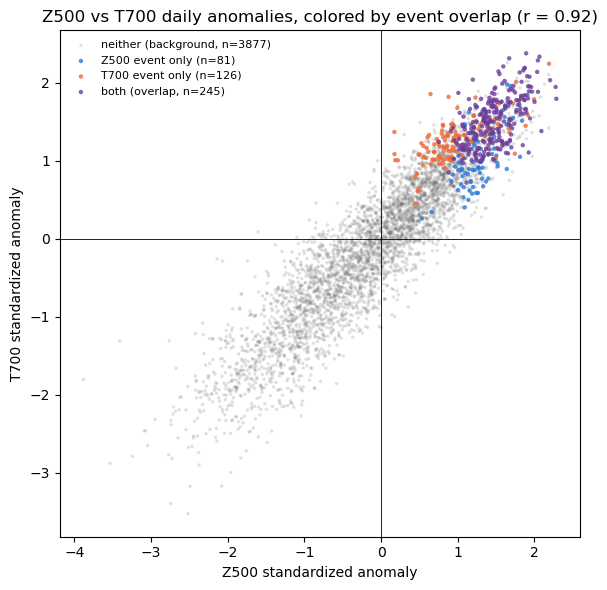

In [19]:
cat = pd.Series('neither', index=df.index)
cat[[d in z_days and d not in t_days for d in df.index]] = 'z_only'
cat[[d in t_days and d not in z_days for d in df.index]] = 't_only'
cat[[d in overlap for d in df.index]] = 'both'

CATCOLOR = {'both': '#6a3d9a', 'z_only': '#2a78d6', 't_only': '#eb6834', 'neither': '0.4'}
CATLABEL = {
    'both': f'both (overlap, n={(cat == "both").sum()})',
    'z_only': f'Z500 event only (n={(cat == "z_only").sum()})',
    't_only': f'T700 event only (n={(cat == "t_only").sum()})',
    'neither': f'neither (background, n={(cat == "neither").sum()})',
}

fig, ax = plt.subplots(figsize=(6, 6))
for c in ['neither', 'z_only', 't_only', 'both']:
    m = cat == c
    ax.scatter(df.loc[m, 'z500_sanom'], df.loc[m, 't700_sanom'],
               s=10 if c != 'neither' else 6, alpha=0.8 if c != 'neither' else 0.2,
               color=CATCOLOR[c], label=CATLABEL[c], edgecolors='none')
ax.axhline(0, color='k', lw=0.6)
ax.axvline(0, color='k', lw=0.6)
ax.set_xlabel('Z500 standardized anomaly')
ax.set_ylabel('T700 standardized anomaly')
ax.set_title(f'Z500 vs T700 daily anomalies, colored by event overlap (r = {corr:.2f})')
ax.legend(frameon=False, fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

Z500 matched events: n=38, mean duration=7.1 d, median=6.5 d
Z500 unmatched events: n=10, mean duration=5.6 d, median=5.0 d
T700 matched events: n=37, mean duration=7.9 d, median=7.0 d
T700 unmatched events: n=12, mean duration=6.5 d, median=6.5 d


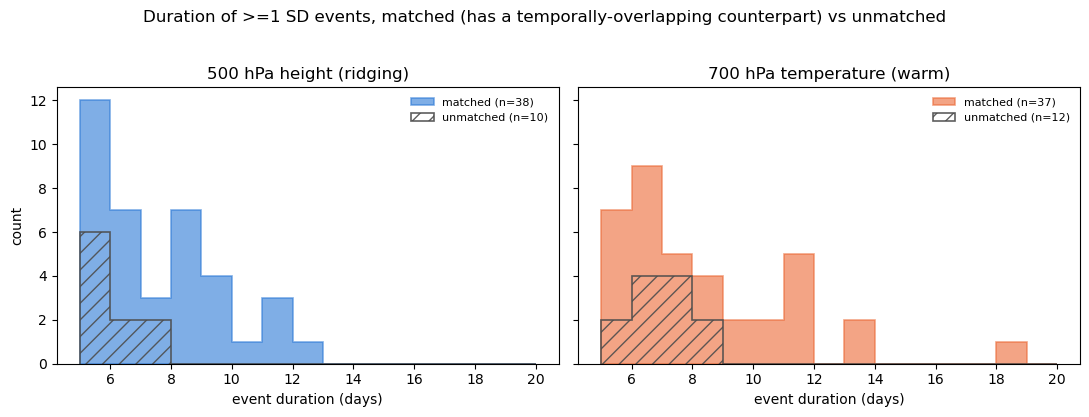

In [20]:
matched_z = z_1sd.loc[~z_1sd.index.isin(unmatched_z.index)]
matched_t = t_1sd.loc[~t_1sd.index.isin(unmatched_t.index)]

print(f'Z500 matched events: n={len(matched_z)}, mean duration={matched_z.duration_days.mean():.1f} d, '
      f'median={matched_z.duration_days.median():.1f} d')
print(f'Z500 unmatched events: n={len(unmatched_z)}, mean duration={unmatched_z.duration_days.mean():.1f} d, '
      f'median={unmatched_z.duration_days.median():.1f} d')
print(f'T700 matched events: n={len(matched_t)}, mean duration={matched_t.duration_days.mean():.1f} d, '
      f'median={matched_t.duration_days.median():.1f} d')
print(f'T700 unmatched events: n={len(unmatched_t)}, mean duration={unmatched_t.duration_days.mean():.1f} d, '
      f'median={unmatched_t.duration_days.median():.1f} d')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
bins = range(5, int(events_df.duration_days.max()) + 3)
for ax, (col, label), matched, unmatched in zip(
    axes, VARS, [matched_z, matched_t], [unmatched_z, unmatched_t]
):
    ax.hist(matched.duration_days, bins=bins, color=COLOR[label], alpha=0.6, edgecolor=COLOR[label],
            linewidth=1.2, label=f'matched (n={len(matched)})', histtype='stepfilled')
    ax.hist(unmatched.duration_days, bins=bins, color='0.3', alpha=0.9, edgecolor='0.3',
            linewidth=1.2, label=f'unmatched (n={len(unmatched)})', histtype='step', hatch='//')
    ax.set_xlabel('event duration (days)')
    ax.set_title(label)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('count')
fig.suptitle('Duration of >=1 SD events, matched (has a temporally-overlapping counterpart) vs unmatched', y=1.03)
plt.tight_layout()
plt.show()

**Interpretation:** unmatched events skew shorter than matched ones (Z500: median
5.0 vs. 6.5 days; T700: median 6.5 vs. 7.0 days), and the scatter shows
unmatched-event days sitting at the lower/inner edge of the same diagonal cloud, not
off of it. Unmatched events look like weaker, more borderline instances of the same
coupled pattern — not a separate population or a broken relationship.

### Event counts, matched vs. unmatched

The original event-count chart (section 4) only has a real bar at 1σ: 2σ and 3σ
produce zero 5-day events in this record (see the note above). Here, the 1σ bar is
split into matched and unmatched counts, so the 79%/76% overlap figures are visible
directly rather than only quoted as a percentage.

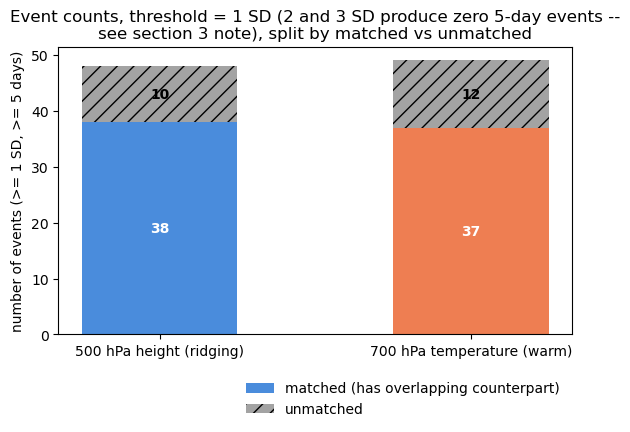

In [21]:
counts = pd.DataFrame({
    'matched': [len(matched_z), len(matched_t)],
    'unmatched': [len(unmatched_z), len(unmatched_t)],
}, index=list(COLOR.keys()))

fig, ax = plt.subplots(figsize=(6, 4.5))
x = np.arange(len(counts))
ax.bar(x, counts['matched'], 0.5, color=[COLOR[l] for l in counts.index], alpha=0.85,
       label='matched (has overlapping counterpart)')
ax.bar(x, counts['unmatched'], 0.5, bottom=counts['matched'], color='0.6', alpha=0.9, hatch='//',
       label='unmatched')
for i, (m, u) in enumerate(zip(counts['matched'], counts['unmatched'])):
    ax.text(i, m / 2, str(m), ha='center', va='center', color='white', fontweight='bold')
    ax.text(i, m + u / 2, str(u), ha='center', va='center', color='black', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(counts.index)
ax.set_ylabel('number of events (>= 1 SD, >= 5 days)')
ax.set_title('Event counts, threshold = 1 SD (2 and 3 SD produce zero 5-day events --\n'
             'see section 3 note), split by matched vs unmatched')
ax.legend(frameon=False, loc='upper right', bbox_to_anchor=(1.0, -0.12))
plt.tight_layout()
plt.show()

### Spatial composite, matched vs. unmatched

Does an unmatched event — one with no overlapping counterpart on the other variable —
look spatially weaker or differently shaped than a matched one, or is it essentially
the same pattern that just fell short of the other variable's threshold that day?

This rebuilds the section-5 composite separately for the matched and unmatched
subsets of each variable, reusing `event_mean_fields()`, `bootstrap_composite_ci()`,
`z500_grid_anom`, and `t700_grid_anom` from section 5. `matched_z`, `unmatched_z`,
`matched_t`, and `unmatched_t` come from the event-level pairing earlier in this
section.

z500 matched: n=38, domain-mean composite = 128.45, fraction not significant = 0.00
z500 unmatched: n=10, domain-mean composite = 122.85, fraction not significant = 0.00
t700 matched: n=37, domain-mean composite = 5.44, fraction not significant = 0.00
t700 unmatched: n=12, domain-mean composite = 5.11, fraction not significant = 0.00


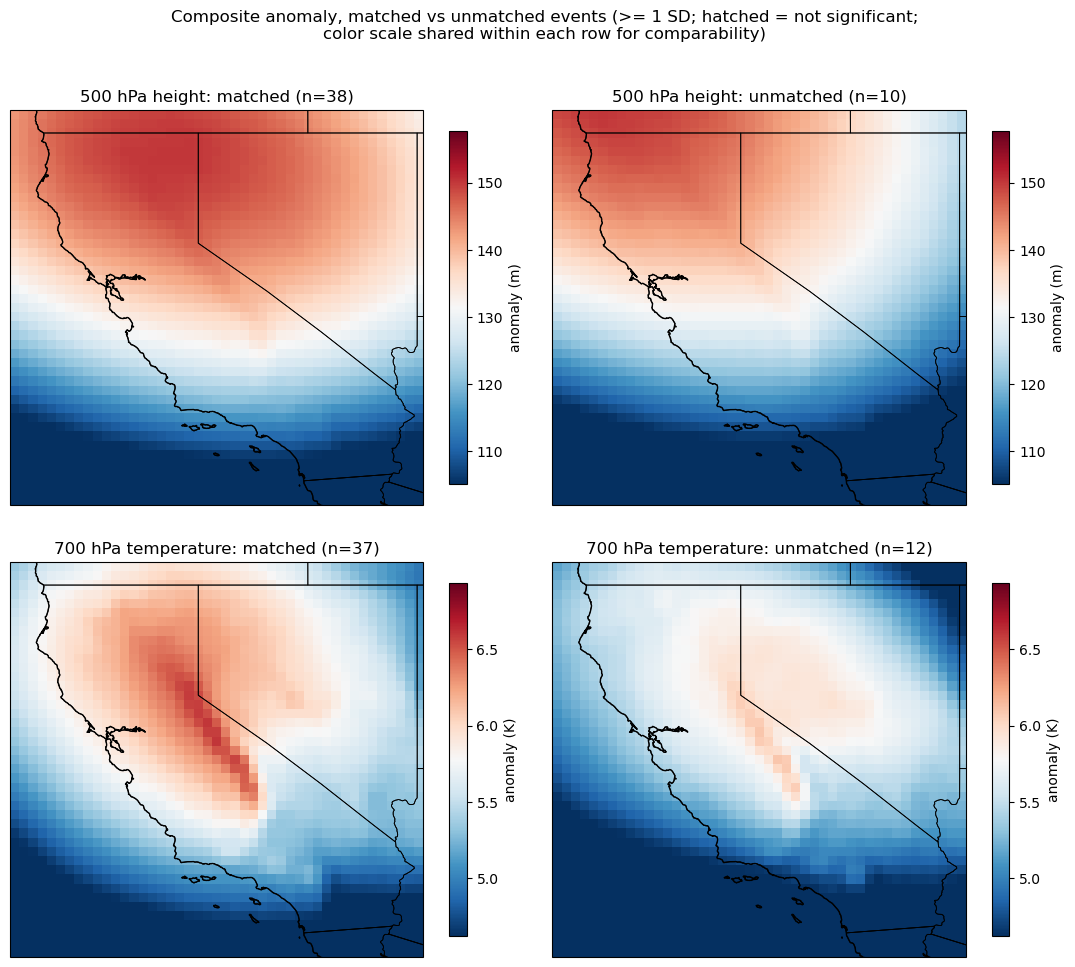

In [22]:
event_subsets = {
    ('z500', 'matched'): matched_z, ('z500', 'unmatched'): unmatched_z,
    ('t700', 'matched'): matched_t, ('t700', 'unmatched'): unmatched_t,
}
grid_anoms = {'z500': z500_grid_anom, 't700': t700_grid_anom}

composites, not_sig_masks = {}, {}
for (col, name), sub in event_subsets.items():
    fields = event_mean_fields(sub, grid_anoms[col], time_index)
    composites[(col, name)] = fields.mean(axis=0)
    ci_lo, ci_hi = bootstrap_composite_ci(fields)
    not_sig_masks[(col, name)] = (ci_lo <= 0) & (ci_hi >= 0)
    print(f'{col} {name}: n={len(sub)}, domain-mean composite = {composites[(col, name)].mean():.2f}, '
          f'fraction not significant = {not_sig_masks[(col, name)].mean():.2f}')

fig, axes = plt.subplots(2, 2, figsize=(11, 10), subplot_kw={'projection': ccrs.PlateCarree()})
row_info = [('z500', '500 hPa height', 'm'), ('t700', '700 hPa temperature', 'K')]
for i, (col, var_label, units) in enumerate(row_info):
    both = np.concatenate([composites[(col, 'matched')].ravel(), composites[(col, 'unmatched')].ravel()])
    vmax = np.abs(both).max() * 1.05  # shared color scale within each row for visual comparability
    for j, name in enumerate(['matched', 'unmatched']):
        ax = axes[i, j]
        pcm = ax.pcolormesh(lon_plot, ds.latitude.values, composites[(col, name)], cmap='RdBu_r',
                             vmin=vmax * 2 / 3., vmax=vmax, shading='auto', transform=ccrs.PlateCarree())
        ax.contourf(lon_plot, ds.latitude.values, not_sig_masks[(col, name)].astype(int), levels=[0.5, 1.5],
                    colors='none', hatches=['...'], transform=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE)
        ax.add_feature(cfeature.STATES, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.6)
        ax.set_title(f'{var_label}: {name} (n={len(event_subsets[(col, name)])})')
        fig.colorbar(pcm, ax=ax, shrink=0.75, label=f'anomaly ({units})')
fig.suptitle('Composite anomaly, matched vs unmatched events (>= 1 SD; hatched = not significant;\n'
             'color scale shared within each row for comparability)', y=1.0)
plt.tight_layout()
plt.show()

**Conclusion (overlap robustness):** combined with the scatter and
duration-histogram findings above, unmatched events show the same spatial pattern as
matched events, just modestly weaker. Across all four diagnostics, there is no
evidence that unmatched events are a distinct physical regime — they are borderline
instances of the same ridging/warming process.

## 6. Sierra Nevada sub-box comparison

The full CA box (32-42.5N, 125-114W) spans coast, Central Valley, and desert — only
part of it is the Sierra Nevada, where snowpack actually accumulates. For snowpack and
drought research, the relevant question is whether the full-box average dilutes or
distorts the ridging signal that matters for the Sierra, or whether it tracks the
Sierra well enough to use as-is.

This section repeats the same box-average, detrended-climatology, and
event-detection pipeline over a tighter Sierra sub-box (36-40N, 121-118.5W, the
western-slope snow zone, already inside the extracted CA-box data) and compares the
two.

In [23]:
SIERRA_LAT_S, SIERRA_LAT_N = 36.0, 40.0
SIERRA_LON_W, SIERRA_LON_E = 239.0, 241.5  # -121.0 to -118.5 deg E -- western-slope snow zone

sierra_weights = np.cos(np.deg2rad(ds.latitude.sel(latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S))))
z500_sierra = ds.z500.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(SIERRA_LON_W, SIERRA_LON_E),
).weighted(sierra_weights).mean(dim=('latitude', 'longitude')).compute()
t700_sierra = ds.t700.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(SIERRA_LON_W, SIERRA_LON_E),
).weighted(sierra_weights).mean(dim=('latitude', 'longitude')).compute()

df_sierra = pd.DataFrame(
    {'z500': z500_sierra.values, 't700': t700_sierra.values},
    index=pd.to_datetime(ds.time.values),
).sort_index()
df_sierra = df_sierra[df_sierra.index.month.isin([1, 2, 3, 4])]

for col in ['z500', 't700']:
    clim_mean, clim_std = climatology_dict(df_sierra.index, df_sierra[col].values)
    m = lookup_climatology(df_sierra.index, clim_mean)
    s = lookup_climatology(df_sierra.index, clim_std)
    trend, slope, intercept = fit_year_trend(df_sierra, col, m, label='Sierra ')
    df_sierra[f'{col}_clim_mean'] = m + trend
    df_sierra[f'{col}_clim_std'] = s
    df_sierra[f'{col}_sanom'] = (df_sierra[col] - df_sierra[f'{col}_clim_mean']) / df_sierra[f'{col}_clim_std']

print(f'\nSierra sub-box: {SIERRA_LAT_S}-{SIERRA_LAT_N}N, '
      f'{360 - SIERRA_LON_E}-{360 - SIERRA_LON_W}W')
df_sierra[['z500_sanom', 't700_sanom']].describe()

Sierra z500: year-trend = +7.169 per decade (p = 0.075, r = 0.30) -- removing this from the climatological baseline before standardizing
Sierra t700: year-trend = +0.181 per decade (p = 0.282, r = 0.18) -- removing this from the climatological baseline before standardizing

Sierra sub-box: 36.0-40.0N, 118.5-121.0W


,z500_sanom,t700_sanom
count,4329.000000,4329.000000
mean,0.000055,-0.000271
std,0.994572,0.995939
min,-3.598342,-3.651735
25%,-0.702435,-0.701923
50%,0.114896,0.089806
75%,0.760483,0.759707
max,2.174271,2.397692


In [24]:
dates_sierra = df_sierra.index
sierra_all_events = []
for col, label in VARS:
    sanom = df_sierra[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates_sierra, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        sierra_all_events.append(ev)

sierra_events_df = pd.concat(sierra_all_events, ignore_index=True)
sierra_events_df = sierra_events_df.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
print(f'Sierra sub-box: {len(sierra_events_df)} events found (same MIN_DURATION/MAX_GAP/THRESHOLDS as the CA box)')
sierra_events_df.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

Sierra sub-box: 101 events found (same MIN_DURATION/MAX_GAP/THRESHOLDS as the CA box)


,,n_events,mean_duration,max_duration
variable,threshold_sd,,,
500 hPa height (ridging),1,46,6.739130,11.0
700 hPa temperature (warm),1,55,7.218182,18.0


Event count comparison, CA box vs Sierra sub-box (>= 1 SD):
                            CA box  Sierra sub-box
variable                                          
500 hPa height (ridging)        48              46
700 hPa temperature (warm)      49              55

z500: CA-box vs Sierra-sub-box standardized-anomaly correlation r = 0.99
t700: CA-box vs Sierra-sub-box standardized-anomaly correlation r = 0.98

CA-box ridging event-days: 326, Sierra ridging event-days: 310, overlap: 292 (94% of the smaller set)
A high correlation/overlap would mean the full CA-box average is a fine proxy for the Sierra; a low one would mean box-averaging is diluting or distorting the signal that actually matters for snowpack.


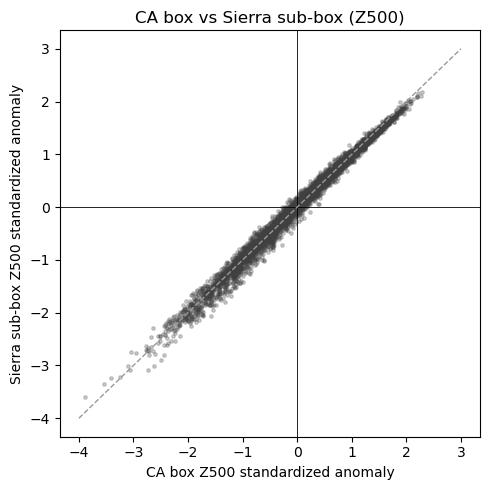

In [25]:
print('Event count comparison, CA box vs Sierra sub-box (>= 1 SD):')
compare = pd.DataFrame({
    'CA box': events_df[events_df.threshold_sd == 1].groupby('variable').size(),
    'Sierra sub-box': sierra_events_df[sierra_events_df.threshold_sd == 1].groupby('variable').size(),
})
print(compare)
print()

for col in ['z500', 't700']:
    r = df[f'{col}_sanom'].corr(df_sierra[f'{col}_sanom'])
    print(f'{col}: CA-box vs Sierra-sub-box standardized-anomaly correlation r = {r:.2f}')


def event_days_from(edf, variable, threshold_sd=1):
    sub = edf[(edf.variable == variable) & (edf.threshold_sd == threshold_sd)]
    days = set()
    for _, row in sub.iterrows():
        days.update(pd.date_range(row.start_date, row.end_date))
    return days


ca_ridge_days = event_days('500 hPa height (ridging)', 1)
sierra_ridge_days = event_days_from(sierra_events_df, '500 hPa height (ridging)', 1)
overlap = ca_ridge_days & sierra_ridge_days
print(f'\nCA-box ridging event-days: {len(ca_ridge_days)}, Sierra ridging event-days: {len(sierra_ridge_days)}, '
      f'overlap: {len(overlap)} ({100 * len(overlap) / min(len(ca_ridge_days), len(sierra_ridge_days)):.0f}% of the smaller set)')
print('A high correlation/overlap would mean the full CA-box average is a fine proxy for '
      'the Sierra; a low one would mean box-averaging is diluting or distorting the '
      'signal that actually matters for snowpack.')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df['z500_sanom'], df_sierra['z500_sanom'], s=6, alpha=0.25, color='0.25')
ax.axhline(0, color='k', lw=0.6)
ax.axvline(0, color='k', lw=0.6)
ax.plot([-4, 3], [-4, 3], color='0.6', lw=1, ls='--')  # 1:1 reference line
ax.set_xlabel('CA box Z500 standardized anomaly')
ax.set_ylabel('Sierra sub-box Z500 standardized anomaly')
ax.set_title('CA box vs Sierra sub-box (Z500)')
plt.tight_layout()
plt.show()

## 7. Precipitation and snowfall validation

Uses `precip_sf_ca_<year>.nc` (produced by `get_precip_sf_ca.py` and
`job_array_get_precip_sf_ca.pbs`): daily total precipitation (TP = large-scale +
convective) and snowfall water-equivalent (SF) over the same CA box, for the same
Jan-Apr 1990-2025 period, derived from ERA5's accumulated surface fields.

**This section is for *relative* comparisons only** (percent of normal, dry vs. wet),
not absolute accuracy. The accumulation-stitching logic in `get_precip_sf_ca.py` was
validated against this notebook's first detected Z500 ridging event (1990-02-21 to
1990-02-25) — box-mean precip stayed within 0.0001-0.009 mm throughout — and against
ERA5's own file-level maxima. A cross-check against the well-documented January 1997
California AR flood showed that ERA5's 0.25° resolution substantially understates the
most extreme, localized orographic station totals, a known ERA5 limitation in steep
terrain.

In [26]:
precip_files = [DATA_DIR / f'precip_sf_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in precip_files if not f.exists()]
if missing:
    raise FileNotFoundError(
        f'{len(missing)} year file(s) missing from {DATA_DIR}: {missing[:5]}...\n'
        'Run job_array_get_precip_sf_ca.pbs first (see get_precip_sf_ca.py).'
    )

ds_precip = xr.open_mfdataset(precip_files, combine='by_coords')
precip_weights = np.cos(np.deg2rad(ds_precip.latitude))
tp_box = ds_precip.tp.weighted(precip_weights).mean(dim=('latitude', 'longitude')).compute()
sf_box = ds_precip.sf.weighted(precip_weights).mean(dim=('latitude', 'longitude')).compute()

df_precip = pd.DataFrame(
    {'tp': tp_box.values, 'sf': sf_box.values},
    index=pd.to_datetime(ds_precip.time.values),
).sort_index()
df_precip = df_precip[df_precip.index.month.isin([1, 2, 3, 4])]


# Deliberately mean only (compute_std=False) and no detrending here -- precip/snowfall
# are zero-inflated and strongly right-skewed, so a parametric sigma threshold doesn't
# apply the way it does for Z500/T700; we only need a 'normal for this day' baseline to
# express actual precip as a ratio/percent of normal. Reuses climatology_dict() /
# lookup_climatology() from section 2 rather than a separate mean-only implementation.
for col in ['tp', 'sf']:
    clim_mean = climatology_dict(df_precip.index, df_precip[col].values, compute_std=False)
    df_precip[f'{col}_clim_mean'] = lookup_climatology(df_precip.index, clim_mean)

print(df_precip.shape, '(should match df.shape -- same Jan-Apr 1990-2025 daily record)')
df_precip[['tp', 'tp_clim_mean', 'sf', 'sf_clim_mean']].describe()

(4329, 4) (should match df.shape -- same Jan-Apr 1990-2025 daily record)


,tp,tp_clim_mean,sf,sf_clim_mean
count,4329.000000,4329.000000,4329.000000,4329.000000
mean,0.150355,0.150484,0.037171,0.037203
std,0.242660,0.041875,0.067872,0.012179
min,0.000000,0.062917,0.000000,0.011432
25%,0.004511,0.109529,0.000085,0.028928
50%,0.043587,0.162304,0.005116,0.039236
75%,0.196217,0.182019,0.043520,0.047413
max,2.200018,0.206863,0.819384,0.055335


In [27]:
from scipy.stats import wilcoxon


def event_mean_ratio(events_sub, df_precip, col):
    """Per-event mean (actual / climatological-normal) -- one value per
    independent *event*, not per day, so the statistical test below doesn't
    repeat the day-level pseudo-replication problem from the composite-map
    section (consecutive days within an event are highly autocorrelated)."""
    vals = []
    for _, row in events_sub.iterrows():
        mask = (df_precip.index.date >= row.start_date) & (df_precip.index.date <= row.end_date)
        actual = df_precip.loc[mask, col].mean()
        normal = df_precip.loc[mask, f'{col}_clim_mean'].mean()
        vals.append(actual / normal if normal > 0 else np.nan)
    return np.array(vals)


print('Is precipitation/snowfall actually suppressed during detected ridging/warm events?')
print('(one-sample Wilcoxon signed-rank test per variable, n = independent events, vs. ratio=1 null)\n')
for col, units in [('tp', 'precip'), ('sf', 'snowfall')]:
    for var_col, label in VARS:
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)]
        ratios = event_mean_ratio(sub_events, df_precip, col)
        ratios = ratios[~np.isnan(ratios)]
        stat, p = wilcoxon(ratios - 1, alternative='less')
        print(f'{units} during {label} events: median = {np.median(ratios) * 100:.0f}% of normal '
              f'(n={len(ratios)} events, one-sided p={p:.2e})')
    print()

Is precipitation/snowfall actually suppressed during detected ridging/warm events?
(one-sample Wilcoxon signed-rank test per variable, n = independent events, vs. ratio=1 null)

precip during 500 hPa height (ridging) events: median = 3% of normal (n=48 events, one-sided p=3.55e-15)
precip during 700 hPa temperature (warm) events: median = 6% of normal (n=49 events, one-sided p=5.77e-09)

snowfall during 500 hPa height (ridging) events: median = 0% of normal (n=48 events, one-sided p=8.14e-10)
snowfall during 700 hPa temperature (warm) events: median = 0% of normal (n=49 events, one-sided p=5.88e-10)



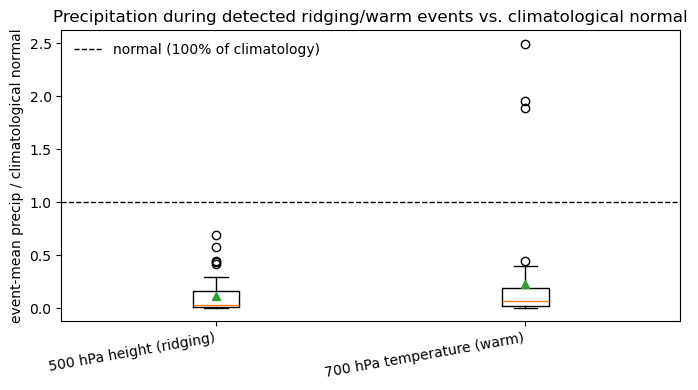

In [28]:
fig, ax = plt.subplots(figsize=(7, 4))
box_data, box_labels = [], []
for col, label in VARS:
    sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)]
    ratios = event_mean_ratio(sub_events, df_precip, 'tp')
    box_data.append(ratios[~np.isnan(ratios)])
    box_labels.append(label)
ax.boxplot(box_data, tick_labels=box_labels, showmeans=True)
ax.axhline(1.0, color='k', ls='--', lw=1, label='normal (100% of climatology)')
ax.set_ylabel('event-mean precip / climatological normal')
ax.set_title('Precipitation during detected ridging/warm events vs. climatological normal')
ax.legend(frameon=False)
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

In [29]:
from scipy.stats import kruskal


def event_decade(events_sub):
    years = events_sub.start_date.apply(lambda d: d.year)
    return pd.cut(years, bins=[1989, 1999, 2009, 2019, 2026], labels=['1990s', '2000s', '2010s', '2020s'])


print('Precip/snowfall ratio-to-normal during ridging/warm events, by decade')
print('(small per-decade n -- indicative, not strongly powered; see Kruskal-Wallis below)\n')

rows = []
for col, units in [('tp', 'precip'), ('sf', 'snowfall')]:
    for var_col, label in VARS:
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)].copy()
        sub_events['ratio'] = event_mean_ratio(sub_events, df_precip, col)
        sub_events['decade'] = event_decade(sub_events)
        for decade, grp in sub_events.groupby('decade', observed=True):
            vals = grp['ratio'].dropna()
            rows.append({
                'metric': units, 'variable': label, 'decade': decade,
                'n_events': len(vals),
                'median_pct_of_normal': round(vals.median() * 100) if len(vals) else np.nan,
            })

decade_table = pd.DataFrame(rows)
decade_pivot = decade_table.pivot_table(
    index=['metric', 'variable'], columns='decade', values='median_pct_of_normal', observed=True,
)
print(decade_pivot.to_string())

print('\nKruskal-Wallis test for a difference in ratio distribution across decades:')
for col, units in [('tp', 'precip'), ('sf', 'snowfall')]:
    for var_col, label in VARS:
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)].copy()
        sub_events['ratio'] = event_mean_ratio(sub_events, df_precip, col)
        sub_events['decade'] = event_decade(sub_events)
        groups = [g['ratio'].dropna().values for _, g in sub_events.groupby('decade', observed=True)]
        groups = [g for g in groups if len(g) >= 3]
        if len(groups) >= 2:
            stat, p = kruskal(*groups)
            print(f'  {units} during {label} events: p = {p:.3f}')

Precip/snowfall ratio-to-normal during ridging/warm events, by decade
(small per-decade n -- indicative, not strongly powered; see Kruskal-Wallis below)

decade                               1990s  2000s  2010s  2020s
metric   variable                                              
precip   500 hPa height (ridging)     13.0    2.0    2.0    2.0
         700 hPa temperature (warm)    5.0    8.0   11.0    7.0
snowfall 500 hPa height (ridging)      0.0    0.0    0.0    0.0
         700 hPa temperature (warm)    0.0    1.0    2.0    1.0

Kruskal-Wallis test for a difference in ratio distribution across decades:
  precip during 500 hPa height (ridging) events: p = 0.173
  precip during 700 hPa temperature (warm) events: p = 0.763
  snowfall during 500 hPa height (ridging) events: p = 0.848
  snowfall during 700 hPa temperature (warm) events: p = 0.014


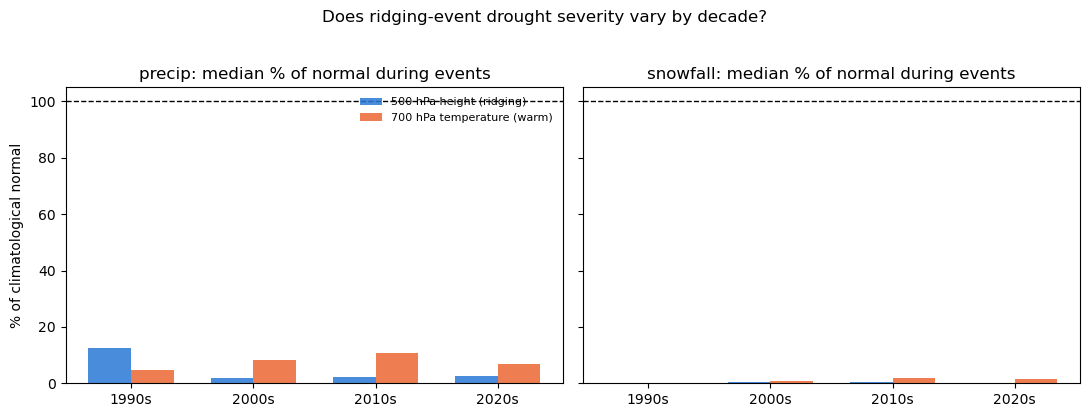

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
decades = ['1990s', '2000s', '2010s', '2020s']
x = np.arange(len(decades))
width = 0.35

for ax, (col, units) in zip(axes, [('tp', 'precip'), ('sf', 'snowfall')]):
    for i, (var_col, label) in enumerate(VARS):
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)].copy()
        sub_events['ratio'] = event_mean_ratio(sub_events, df_precip, col)
        sub_events['decade'] = event_decade(sub_events)
        medians = sub_events.groupby('decade', observed=True)['ratio'].median().reindex(decades) * 100
        ax.bar(x + (i - 0.5) * width, medians.values, width, label=label, color=COLOR[label], alpha=0.85)
    ax.axhline(100, color='k', ls='--', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(decades)
    ax.set_title(f'{units}: median % of normal during events')
axes[0].set_ylabel('% of climatological normal')
axes[0].legend(frameon=False, fontsize=8, loc='upper right')
fig.suptitle('Does ridging-event drought severity vary by decade?', y=1.03)
plt.tight_layout()
plt.show()

## 8. 2026 out-of-sample test

Everything above (climatology, trend fit, event-detection thresholds) is fit on
1990-2025 only — `YEARS` deliberately excludes 2026 (see section 1). This section
does **not** refit anything on 2026 data.

It extracts the same CA-box Z500/T700/precipitation/snowfall fields for January-April
2026 (`z500_t700_ca_2026.nc`, `precip_sf_ca_2026.nc`, from the same extraction scripts
used for every other year), and scores them against the **frozen** 1990-2025
climatology, standard deviation, and linear year-trend — extrapolating the trend one
point beyond the data it was fit on, rather than re-estimating it with 2026 included.

This is the appropriate way to ask how extreme the March 2026 Western US heat wave
(`March_2026_Western-US-Heat Wave.pdf`, Davis et al.) was relative to this 36-year
record, without letting the event itself inflate the baseline it is judged against.

In [31]:
YEAR_2026 = 2026  # held out of YEARS above -- never touches the fit

files_2026 = [DATA_DIR / f'z500_t700_ca_{YEAR_2026}.nc']
missing = [f.name for f in files_2026 if not f.exists()]
if missing:
    raise FileNotFoundError(f'{missing} missing -- run get_z500_t700_ca.py {YEAR_2026} first')

ds26 = xr.open_dataset(files_2026[0])
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
t700_26 = ds26.t700.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame(
    {'z500': z500_26.values, 't700': t700_26.values},
    index=pd.to_datetime(ds26.time.values),
).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]

for col in ['z500', 't700']:
    # climatology_dict/lookup_climatology/fit_year_trend all reused from section 2 --
    # df = 1990-2025, frozen; verbose=False just avoids reprinting the same trend-fit
    # diagnostic section 2 already printed once.
    clim_mean, clim_std = climatology_dict(df.index, df[col].values)
    m = lookup_climatology(df.index, clim_mean)
    _, slope, intercept = fit_year_trend(df, col, m, verbose=False)
    clim_mean_arr = lookup_climatology(df26.index, clim_mean)
    clim_std_arr = lookup_climatology(df26.index, clim_std)
    trend_2026 = intercept + slope * YEAR_2026                # extrapolated one point beyond the fit
    df26[f'{col}_clim_mean'] = clim_mean_arr + trend_2026
    df26[f'{col}_clim_std'] = clim_std_arr
    df26[f'{col}_sanom'] = (df26[col] - df26[f'{col}_clim_mean']) / clim_std_arr

print('2026 standardized-anomaly summary (scored against the FROZEN 1990-2025 baseline):')
df26[['z500_sanom', 't700_sanom']].describe()

2026 standardized-anomaly summary (scored against the FROZEN 1990-2025 baseline):


,z500_sanom,t700_sanom
count,120.000000,120.000000
mean,0.496638,0.653661
std,1.095318,1.151423
min,-2.016382,-1.775045
25%,-0.283365,-0.205697
50%,0.663746,0.687184
75%,1.340154,1.526804
max,2.746836,3.128170


In [32]:
print(f"Peak Z500 standardized anomaly in 2026: {df26['z500_sanom'].max():.2f} sigma, on {df26['z500_sanom'].idxmax().date()}")
print(f"Peak T700 standardized anomaly in 2026: {df26['t700_sanom'].max():.2f} sigma, on {df26['t700_sanom'].idxmax().date()}")

Peak Z500 standardized anomaly in 2026: 2.75 sigma, on 2026-03-19
Peak T700 standardized anomaly in 2026: 3.13 sigma, on 2026-03-19


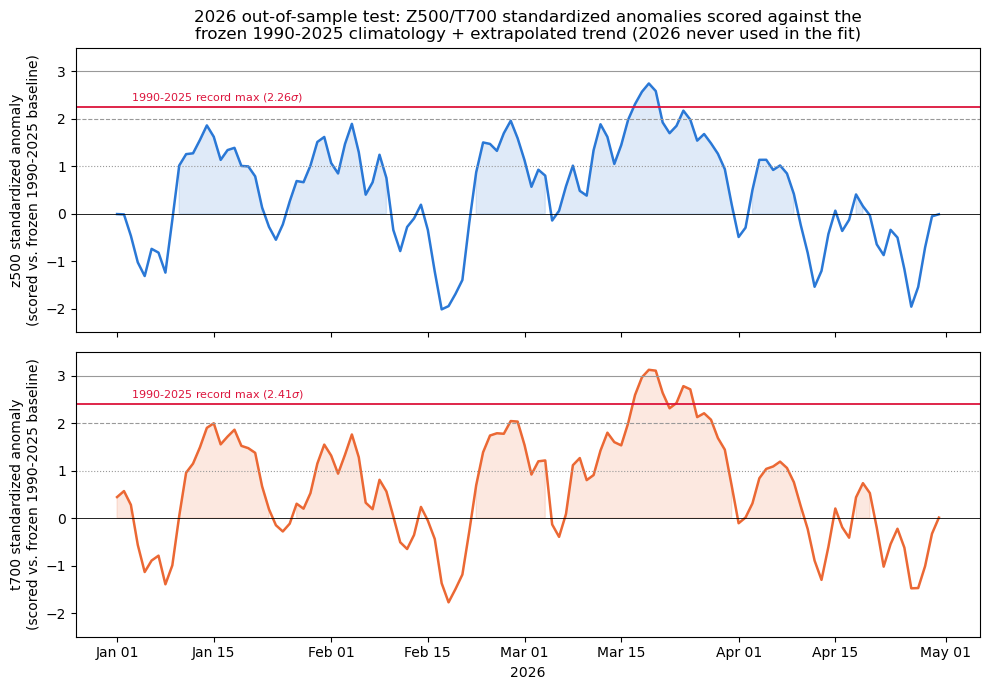

In [33]:
hist_max = {'z500': 2.26, 't700': 2.41}  # 1990-2025 record max (see the note in section 3)
COLOR2 = {'z500': '#2a78d6', 't700': '#eb6834'}
LABEL2 = {'z500': '500 hPa height (ridging)', 't700': '700 hPa temperature (warm)'}

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, col in zip(axes, ['z500', 't700']):
    ax.plot(df26.index, df26[f'{col}_sanom'], color=COLOR2[col], lw=1.8, label=LABEL2[col])
    for thr, ls in zip([1, 2, 3], [':', '--', '-']):
        ax.axhline(thr, color='0.6', lw=0.8, ls=ls)
    ax.axhline(hist_max[col], color='crimson', lw=1.3, ls='-')
    ax.text(df26.index[2], hist_max[col] + 0.05, f'1990-2025 record max ({hist_max[col]:.2f}$\\sigma$)',
            color='crimson', fontsize=8, va='bottom')
    ax.fill_between(df26.index, 0, df26[f'{col}_sanom'], where=df26[f'{col}_sanom'] > 0,
                     color=COLOR2[col], alpha=0.15)
    ax.set_ylabel(f'{col} standardized anomaly\n(scored vs. frozen 1990-2025 baseline)')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_ylim(-2.5, 3.5)
axes[0].set_title('2026 out-of-sample test: Z500/T700 standardized anomalies scored against the\n'
                   'frozen 1990-2025 climatology + extrapolated trend (2026 never used in the fit)')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[-1].set_xlabel('2026')
fig.tight_layout()
plt.show()

In [34]:
dates26 = df26.index
events_2026 = []
for col, label in VARS:
    sanom = df26[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates26, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        events_2026.append(ev)
events_2026_df = pd.concat(events_2026, ignore_index=True)
print(f'{len(events_2026_df)} events detected in 2026 alone '
      f'(MIN_DURATION={MIN_DURATION}, MAX_GAP={MAX_GAP}, thresholds={THRESHOLDS}, same pipeline as section 3)')
events_2026_df

9 events detected in 2026 alone (MIN_DURATION=5, MAX_GAP=1, thresholds=[1, 2, 3], same pipeline as section 3)


,variable,threshold_sd,start_date,end_date,duration_days,n_gap_days,peak_sanom,mean_sanom
0,500 hPa height (ridging),1,2026-01-10,2026-01-19,10.0,0.0,1.862128,1.346190
1,500 hPa height (ridging),1,2026-01-29,2026-02-05,8.0,1.0,1.895482,1.340588
2,500 hPa height (ridging),1,2026-02-23,2026-03-01,7.0,0.0,1.960304,1.525237
3,500 hPa height (ridging),1,2026-03-11,2026-03-29,19.0,0.0,2.746836,1.849576
4,700 hPa temperature (warm),1,2026-01-12,2026-01-21,10.0,0.0,2.000548,1.606612
5,700 hPa temperature (warm),1,2026-01-30,2026-02-05,7.0,1.0,1.764779,1.334852
6,700 hPa temperature (warm),1,2026-02-23,2026-03-04,10.0,1.0,2.046964,1.565962
7,700 hPa temperature (warm),1,2026-03-12,2026-03-30,19.0,0.0,3.128170,2.242438
8,700 hPa temperature (warm),2,2026-03-16,2026-03-28,13.0,0.0,3.128170,2.546709


In [35]:
hist_max_sanom = {'z500': 2.26, 't700': 2.41}  # from the note in section 3 (pre-2026 record)
hist_max_dur = {'z500': 12, 't700': 18}

for col in ['z500', 't700']:
    peak = df26[f'{col}_sanom'].max()
    print(f'{col}: 2026 peak = {peak:.2f} sigma vs 1990-2025 record max {hist_max_sanom[col]:.2f} sigma '
          f'(exceeds by {peak - hist_max_sanom[col]:.2f})')

biggest = {}
for col, label in VARS:
    sub = events_2026_df[(events_2026_df.variable == label) & (events_2026_df.threshold_sd == 1)]
    biggest[col] = sub.loc[sub.duration_days.idxmax()]
    print(f'{col}: 2026 longest >=1SD event = {biggest[col].duration_days:.0f} days '
          f'({biggest[col].start_date} to {biggest[col].end_date}) vs 1990-2025 record max {hist_max_dur[col]} days')

t700_2sd = events_2026_df[(events_2026_df.variable == '700 hPa temperature (warm)') & (events_2026_df.threshold_sd == 2)]
print(f'T700 >=2SD events in 2026: {len(t700_2sd)}, longest = '
      f'{t700_2sd.duration_days.max() if len(t700_2sd) else 0:.0f} days '
      f'(1990-2025 record: 2-sigma never persisted beyond 2-3 days)')

z500: 2026 peak = 2.75 sigma vs 1990-2025 record max 2.26 sigma (exceeds by 0.49)
t700: 2026 peak = 3.13 sigma vs 1990-2025 record max 2.41 sigma (exceeds by 0.72)
z500: 2026 longest >=1SD event = 19 days (2026-03-11 to 2026-03-29) vs 1990-2025 record max 12 days
t700: 2026 longest >=1SD event = 19 days (2026-03-12 to 2026-03-30) vs 1990-2025 record max 18 days
T700 >=2SD events in 2026: 1, longest = 13 days (1990-2025 record: 2-sigma never persisted beyond 2-3 days)


In [36]:
precip_files_2026 = [DATA_DIR / f'precip_sf_ca_{YEAR_2026}.nc']
missing = [f.name for f in precip_files_2026 if not f.exists()]
if missing:
    raise FileNotFoundError(f'{missing} missing -- run get_precip_sf_ca.py {YEAR_2026} first')

ds26p = xr.open_dataset(precip_files_2026[0])
weights26p = np.cos(np.deg2rad(ds26p.latitude))
tp_26 = ds26p.tp.weighted(weights26p).mean(dim=('latitude', 'longitude')).compute()
sf_26 = ds26p.sf.weighted(weights26p).mean(dim=('latitude', 'longitude')).compute()
df26p = pd.DataFrame(
    {'tp': tp_26.values, 'sf': sf_26.values}, index=pd.to_datetime(ds26p.time.values),
).sort_index()
df26p = df26p[df26p.index.month.isin([1, 2, 3, 4])]


# climatology_dict()/lookup_climatology() reused from section 2 (mean-only, same
# compute_std=False choice as section 7 -- precip/snowfall aren't detrended or
# standardized, just expressed as a ratio to a frozen 1990-2025 "normal").
for col in ['tp', 'sf']:
    clim_mean = climatology_dict(df_precip.index, df_precip[col].values, compute_std=False)  # df_precip = 1990-2025, frozen (section 7)
    df26p[f'{col}_clim_mean'] = lookup_climatology(df26p.index, clim_mean)


def ratio_for_window(df, lo, hi, col):
    mask = (df.index.date >= pd.Timestamp(lo).date()) & (df.index.date <= pd.Timestamp(hi).date())
    actual = df.loc[mask, col].mean()
    normal = df.loc[mask, f'{col}_clim_mean'].mean()
    return actual, normal, (actual / normal * 100 if normal > 0 else np.nan)


z_big = biggest['z500']
print(f'Biggest 2026 Z500 ridging event: {z_big.start_date} to {z_big.end_date} '
      f'({z_big.duration_days:.0f} days, peak {z_big.peak_sanom:.2f} sigma)')
for col, name in [('tp', 'precip'), ('sf', 'snowfall')]:
    a, n, pct = ratio_for_window(df26p, z_big.start_date, z_big.end_date, col)
    print(f'  {name} during this event: actual={a:.4f} mm/day, normal={n:.4f} mm/day '
          f'-> {pct:.0f}% of (frozen 1990-2025) climatological normal')

Biggest 2026 Z500 ridging event: 2026-03-11 to 2026-03-29 (19 days, peak 2.75 sigma)
  precip during this event: actual=0.0020 mm/day, normal=0.1429 mm/day -> 1% of (frozen 1990-2025) climatological normal
  snowfall during this event: actual=0.0000 mm/day, normal=0.0334 mm/day -> 0% of (frozen 1990-2025) climatological normal


**Conclusion:** scored against the frozen 1990-2025 baseline (2026 never touched
the climatology, the trend fit, or the event thresholds), March 2026 is not just
another entry in the historical distribution. It sets a new record on every measure
this notebook's pipeline tracks:
- **Peak magnitude:** Z500 reaches 2.75σ (prior record 2.26σ); T700 reaches 3.13σ (prior record 2.41σ) — the first time either variable has crossed 3σ in this 36-year record.
- **Persistence:** the March event is the single longest Z500/T700 ridging/warm episode on record (19 days, vs. a 1990-2025 maximum of 12/18 days), and the first sustained (13-day) run above 2σ for T700 — a persistence level the pre-2026 record showed as "essentially never happens" (see the note in section 5).
- **Surface impact:** precipitation and snowfall collapsed to about 1%/0% of the frozen climatological normal during the event itself, consistent with the paper's basin snowpack figures (3%, 11%, 41% of normal by March 28, 2026).

This is an honest out-of-sample test, not a post-hoc fit. The framing of March 2026 as
a genuinely exceptional — not garden-variety — blocking event (Davis et al.) holds up
against the full 36-year statistical baseline built in sections 1-7.